[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L6/BA_L6_cars/BA_L6_cars.ipynb)

# BA_L6_cars: Which CARs are significant? Ether around 13 Ethereum upgrades

*Quantlet of Lecture 6, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Cumulative abnormal returns CAR[-1,+1] of Ether at the schedule and implementation dates of 13 Ethereum upgrades (market model against an equal-weighted index of 11 coins, estimation window [-250, -31]) with the 5% band of each event, and the cross-sectional and sign tests.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Method

Market model on days $[-250, -31]$, $R_t = \alpha + \beta R_{m,t} + u_t$; abnormal return $\mathrm{AR}_t = R_t - \hat\alpha - \hat\beta R_{m,t}$;
$\mathrm{CAR}[-1, +1]$ is the sum over days $-1, 0, +1$. One event is significant at 5% when $|\mathrm{CAR}| > 1.96\,\hat\sigma_u\sqrt 3$.
The cross-sectional test of the 13 implementation CARs is $t_{CS} = \overline{\mathrm{CAR}}/(s_{\mathrm{CAR}}/\sqrt{13})$; the sign test compares the
number of positive CARs with $\mathrm{Bin}(13, 0.5)$. Data: ETH and 11 other coins, EODHD daily closes to 23 October 2026.

Outside the 5% band: 3 of 26 dates (Gray Glacier schedule, Merge implementation, Pectra implementation); expected by chance: 1.3
Band from 5.2% to 12.6%
Implementation: mean CAR -0.18%, s_CAR 6.50%, t_CS -0.10, p 0.92; 7 of 13 positive, sign test p 1.00


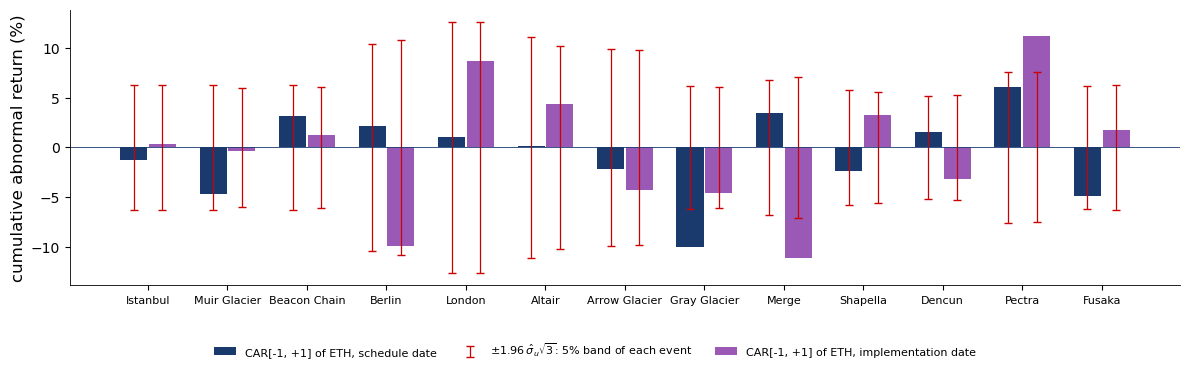

In [5]:
EV = [('Istanbul', '2019-11-20', '2019-12-08'), ('Muir Glacier', '2019-11-22', '2020-01-02'), ('Beacon Chain', '2020-11-04', '2020-12-01'),
      ('Berlin', '2021-03-08', '2021-04-15'), ('London', '2021-07-15', '2021-08-05'), ('Altair', '2021-10-05', '2021-10-27'),
      ('Arrow Glacier', '2021-11-10', '2021-12-09'), ('Gray Glacier', '2022-06-16', '2022-06-30'), ('Merge', '2022-08-24', '2022-09-15'),
      ('Shapella', '2023-03-28', '2023-04-12'), ('Dencun', '2024-02-27', '2024-03-13'), ('Pectra', '2025-04-23', '2025-05-07'),
      ('Fusaka', '2025-11-06', '2025-12-03')]          # (family, formal schedule date, implementation date)
MKT = ['BTC', 'XRP', 'BNB', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'XMR']
RE = (100 * np.log(pd.DataFrame({c: px(f'{c}-USD.CC') for c in ['ETH'] + MKT}))).diff().loc['2018-06-01':].dropna()
r_eth, r_m = RE['ETH'], RE[MKT].mean(axis=1)
idx = {d: i for i, d in enumerate(RE.index)}
rows = []
for name, sd, imp in EV:
    for stage, d0 in [('schedule', sd), ('implementation', imp)]:
        i0 = idx[pd.Timestamp(d0)]
        est = slice(i0 - 250, i0 - 30)
        X = np.column_stack([np.ones(220), r_m.iloc[est].values]); y = r_eth.iloc[est].values
        b = np.linalg.lstsq(X, y, rcond=None)[0]
        s2 = ((y - X @ b) ** 2).sum() / 218
        car = (r_eth.iloc[i0 - 1:i0 + 2] - b[0] - b[1] * r_m.iloc[i0 - 1:i0 + 2]).sum()
        rows.append(dict(event=name, stage=stage, car=car, band=1.96 * np.sqrt(3 * s2), t=car / np.sqrt(3 * s2)))
T = pd.DataFrame(rows)
out = T[T.car.abs() > T.band]
print(f'Outside the 5% band: {len(out)} of 26 dates ({", ".join(out.event + " " + out.stage)}); expected by chance: 1.3')
print(f'Band from {T.band.min():.1f}% to {T.band.max():.1f}%')
c = T[T.stage == 'implementation'].car
tcs = c.mean() / (c.std(ddof=1) / np.sqrt(13))
print(f'Implementation: mean CAR {c.mean():.2f}%, s_CAR {c.std(ddof=1):.2f}%, t_CS {tcs:.2f}, p {2 * stats.t.sf(abs(tcs), 12):.2f}; '
      f'{(c > 0).sum()} of 13 positive, sign test p {stats.binomtest(int((c > 0).sum()), 13, 0.5).pvalue:.2f}')

fig, ax = plt.subplots(figsize=(12, 3.7))
xx = np.arange(len(EV))
for k, (stage, col, off) in enumerate([('schedule', BLUE, -0.18), ('implementation', ETH, 0.18)]):
    tab = T[T.stage == stage]
    ax.bar(xx + off, tab['car'], 0.34, color=col, label=f'CAR[-1, +1] of ETH, {stage} date')
    ax.errorbar(xx + off, np.zeros(len(EV)), yerr=tab['band'], fmt='none', ecolor=RED, elinewidth=0.9, capsize=3,
                label=('$\\pm 1.96\\,\\hat\\sigma_u\\sqrt{3}$: 5% band of each event' if k == 0 else None))
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_xticks(xx); ax.set_xticklabels([e[0] for e in EV], fontsize=8)
ax.set_ylabel('cumulative abnormal return (%)')
slide_fig(fig, 'ba_l6_cars', 0.12, ncol=3)

**How to read it.** Three of 26 CARs leave their own band, about what chance gives at 5%; the two significant implementation CARs (Merge,
Pectra) have opposite signs, and the mean of the 13 is close to zero.